In [2]:
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/data
!cp /content/drive/MyDrive/text-to-sound/data/* /content/data/
!ls -lh /content/data

CKPT = "/content/drive/MyDrive/text-to-sound/checkpoints/"

Mounted at /content/drive
total 1.2G
-rw------- 1 root root 1.3M Nov  6 19:40 captions_dev.csv
-rw------- 1 root root  25M Nov  6 19:40 clap_audio.npy
-rw------- 1 root root 125M Nov  6 19:40 clap_text.npy
-rw------- 1 root root 995M Nov  6 19:41 mels.npy
-rw------- 1 root root  136 Nov  6 19:41 mel_stats.npy
-rw------- 1 root root 952K Nov  6 19:41 meta.csv


In [3]:
import torch
import glob
import pandas as pd
import os
from IPython.display import Audio, display
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
import random
!test -d BigVGAN || git clone -q https://github.com/NVIDIA/BigVGAN
!sed -i 's/proxies: Optional\[Dict\],/proxies: Optional[Dict] = None,/; s/resume_download: bool,/resume_download: bool = False,/' BigVGAN/bigvgan.py
!grep -n "proxies\|resume_download" BigVGAN/bigvgan.py
import sys; sys.path.insert(0, "BigVGAN")
import torch, bigvgan
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import math
import torch.nn as nn
from transformers import ClapModel, ClapProcessor
%matplotlib inline
device = "cuda"
vocoder = bigvgan.BigVGAN.from_pretrained("nvidia/bigvgan_v2_22khz_80band_256x", use_cuda_kernel = False)
vocoder.remove_weight_norm()
vocoder = vocoder.eval().to(device)
print(vocoder.h.sampling_rate)

DATA = "/content/data/"
mels = np.load(DATA + "mels.npy", mmap_mode = "r")
stats = np.load(DATA + "mel_stats.npy")
MIN, MAX = stats[0], stats[1]
meta = pd.read_csv(DATA + "meta.csv")

422:        proxies: Optional[Dict] = None,
423:        resume_download: bool = False,
444:                proxies=proxies,
445:                resume_download=resume_download,
476:                proxies=proxies,
477:                resume_download=resume_download,


config.json:   0%|          | 0.00/1.41k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `hf_hub_download`. Downloads always resume whenever possible.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights from nvidia/bigvgan_v2_22khz_80band_256x


bigvgan_generator.pt: reconstructing file:   0%|          |  0.00B /  449MB            

bigvgan_generator.pt: downloading bytes:           |  0.00B            

Removing weight norm...
22050


In [4]:
class MelDataset(Dataset):
    def __init__(self, split):
        self.rows = meta.index[meta["split"] == split].to_numpy()
        self.audio = np.load(DATA + "clap_audio.npy")
        self.mels = np.load(DATA + "mels.npy")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows[i]
        mel = torch.tensor(self.mels[row].astype("float32"))
        clap = torch.tensor(self.audio[row].astype("float32"))
        clap = F.normalize(clap, dim = 0)
        return mel, clap

train_data = MelDataset("train")
loader = DataLoader(train_data, batch_size = 32, shuffle = True, num_workers = 2)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

In [5]:
mel, clap = next(iter(loader))
m = mel[0]
m = ((m + 1) / 2) * (MAX - MIN) + MIN
m = m.to(device)

with torch.inference_mode():
    wav = vocoder(m)
wav = wav.squeeze().cpu().numpy()
Audio(wav, rate = 22050)

In [6]:
class Autoencoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder = nn.Sequential(
      nn.Conv2d(1, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 128, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(128, 128, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(128, 256, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(256, 256, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(256, 8, 3, 1, 1),
    )
    self.decoder = nn.Sequential(
        nn.Conv2d(4, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(256, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(256, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(128, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(128, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 1, 3, 1, 1),
    )
  def forward(self, x):
    mu, logvar = self.encoder(x).chunk(2, dim = 1)
    z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    return self.decoder(z), mu, logvar

In [ ]:
%%script false --no-raise-error

model = Autoencoder().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 1e-3)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

EPOCHS = 2000
for epoch in range(EPOCHS):
  for mel, clap in tiny_loader:
    x = mel.to(device)
    out, mu, logvar = model(x)
    recon = F.l1_loss(out, x)
    kl = -0.5 * torch.mean(1 + logvar - mu ** 2 - torch.exp(logvar))
    loss = recon + 1e-6 * kl
    opt.zero_grad()
    loss.backward()
    opt.step()
  if epoch % 100 == 0:
    print(epoch, loss.item())

print(mu.mean().item(), mu.std().item(), logvar.mean().item())
print(recon.item(), kl.item())

In [7]:
model = Autoencoder().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 2e-4)

EPOCHS = 20
for epoch in range(EPOCHS):
  total_recon, total_kl = 0, 0
  for mel, clap in tqdm(loader):
    x = mel.to(device)
    out, mu, logvar = model(x)
    recon = F.l1_loss(out, x)
    kl = -0.5 * torch.mean(1 + logvar - mu ** 2 - torch.exp(logvar))
    loss = recon + 1e-5 * kl
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    total_recon += recon.item()
    total_kl += kl.item()
  print(epoch, total_recon / len(loader), total_kl / len(loader), mu.std().item())
  torch.save(model.state_dict(), CKPT + "vae_20ep.pt")

  0%|          | 0/714 [00:00<?, ?it/s]

KeyboardInterrupt: 

0.026399243623018265


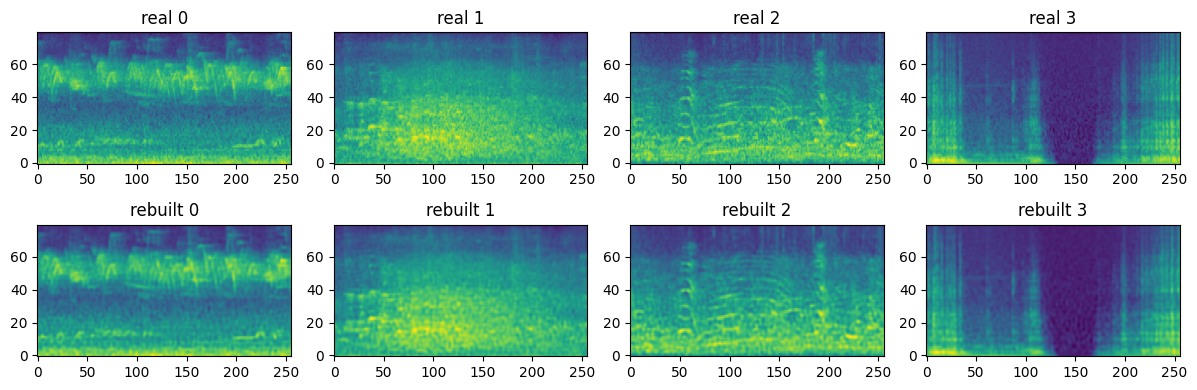

originals


reconstructions


In [ ]:
val_data = MelDataset("val")
val_loader = DataLoader(Subset(val_data, [0, 500, 1000, 1500]), batch_size = 4)
real, _ = next(iter(val_loader))
real = real.to(device)
model.eval()
with torch.no_grad():
    mu, _ = model.encoder(real).chunk(2, dim = 1)
    rebuilt = model.decoder(mu).clamp(-1, 1)
print(F.l1_loss(rebuilt, real).item())

fig, axes = plt.subplots(2, 4, figsize = (12, 4))
for i in range(4):
    axes[0, i].imshow(real[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[0, i].set_title(f"real {i}")
    axes[1, i].imshow(rebuilt[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[1, i].set_title(f"rebuilt {i}")
plt.tight_layout()
plt.show()

m = ((real + 1) / 2) * (MAX - MIN) + MIN
print("originals")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

m = ((rebuilt + 1) / 2) * (MAX - MIN) + MIN
print("reconstructions")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

In [8]:
class Discriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1 = nn.Conv2d(1, 64, 4, 2, 1)
    self.layer2 = nn.Conv2d(64, 128, 4, 2, 1)
    self.layer3 = nn.Conv2d(128, 256, 4, 2, 1)
    self.layer4 = nn.Conv2d(256, 1, 3, 1, 1)
    self.leaky = nn.LeakyReLU(0.2)
  def forward(self, x):
    x = self.leaky(self.layer1(x))
    x = self.leaky(self.layer2(x))
    x = self.leaky(self.layer3(x))
    x = self.layer4(x)
    return x

torch.Size([32, 1, 10, 32])


In [17]:
model = Autoencoder().to(device)
model.load_state_dict(torch.load(CKPT + "vae_gan.pt", map_location = device))
for p in model.encoder.parameters():
  p.requires_grad = False

D = Discriminator().to(device)
D.load_state_dict(torch.load(CKPT + "disc.pt", map_location = device))
opt_g = torch.optim.Adam(model.decoder.parameters(), lr = 1e-4, betas = (0.5, 0.9))
opt_d = torch.optim.Adam(D.parameters(), lr = 4e-4, betas = (0.5, 0.9))
adv_weight = 0.01

EPOCHS = 3
step = 0
for epoch in range(EPOCHS):
  for i, (mel, clap) in enumerate(tqdm(loader)):
    x = mel.to(device)
    with torch.no_grad():
      mu, logvar = model.encoder(x).chunk(2, dim = 1)
      z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    fake = model.decoder(z)

    d_real = D(x)
    d_fake = D(fake.detach())
    d_loss = F.relu(1 - d_real).mean() + F.relu(1 + d_fake).mean()
    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()
    recon = F.l1_loss(fake, x)
    adv = -D(fake).mean()

    if step >= 0:
      g_loss = recon + adv_weight * adv
      opt_g.zero_grad()
      g_loss.backward()
      torch.nn.utils.clip_grad_norm_(model.decoder.parameters(), 1.0)
      opt_g.step()
    step += 1
    if i % 100 == 0:
      print(f"{step:4d} | recon {recon.item():.4f} | adv {adv.item():+.3f} | "f"d_loss {d_loss.item():.3f} | D(real) {d_real.mean().item():+.2f} | D(fake) {d_fake.mean().item():+.2f}")
  torch.save(model.state_dict(), CKPT + "vae_gan2.pt")
  torch.save(D.state_dict(), CKPT + "disc2.pt")

  0%|          | 0/714 [00:00<?, ?it/s]

   1 | recon 0.0298 | adv +0.917 | d_loss 2.157 | D(real) +1.01 | D(fake) +0.92
 101 | recon 0.0279 | adv -1.069 | d_loss 2.072 | D(real) -1.04 | D(fake) -1.30
 201 | recon 0.0316 | adv -0.028 | d_loss 1.987 | D(real) -0.17 | D(fake) -0.19
 301 | recon 0.0300 | adv -0.055 | d_loss 1.797 | D(real) -0.43 | D(fake) -0.67
 401 | recon 0.0313 | adv -0.150 | d_loss 1.839 | D(real) +0.33 | D(fake) +0.17
 501 | recon 0.0330 | adv -1.253 | d_loss 1.912 | D(real) -0.51 | D(fake) -0.67
 601 | recon 0.0308 | adv +0.468 | d_loss 1.904 | D(real) +0.17 | D(fake) +0.07
 701 | recon 0.0298 | adv +1.407 | d_loss 1.620 | D(real) +0.33 | D(fake) -0.05


  0%|          | 0/714 [00:00<?, ?it/s]

 715 | recon 0.0326 | adv -0.175 | d_loss 1.977 | D(real) +0.04 | D(fake) +0.01
 815 | recon 0.0307 | adv +0.138 | d_loss 1.948 | D(real) -0.06 | D(fake) -0.11
 915 | recon 0.0290 | adv +0.562 | d_loss 1.798 | D(real) +0.09 | D(fake) -0.12
1015 | recon 0.0329 | adv -0.618 | d_loss 2.281 | D(real) -0.98 | D(fake) -0.92
1115 | recon 0.0307 | adv +1.017 | d_loss 1.647 | D(real) +0.18 | D(fake) -0.19
1215 | recon 0.0330 | adv -0.531 | d_loss 2.549 | D(real) +1.13 | D(fake) +1.39
1315 | recon 0.0308 | adv -0.037 | d_loss 1.832 | D(real) +0.36 | D(fake) +0.19
1415 | recon 0.0316 | adv +0.135 | d_loss 1.984 | D(real) +0.07 | D(fake) +0.05


  0%|          | 0/714 [00:00<?, ?it/s]

1429 | recon 0.0336 | adv -0.683 | d_loss 2.179 | D(real) +0.42 | D(fake) +0.58
1529 | recon 0.0329 | adv -0.025 | d_loss 2.065 | D(real) +0.03 | D(fake) +0.09
1629 | recon 0.0304 | adv +0.050 | d_loss 1.882 | D(real) +0.16 | D(fake) +0.02
1729 | recon 0.0326 | adv -0.176 | d_loss 1.983 | D(real) +0.38 | D(fake) +0.35
1829 | recon 0.0306 | adv +0.491 | d_loss 1.698 | D(real) -0.31 | D(fake) -0.63
1929 | recon 0.0307 | adv +0.159 | d_loss 1.780 | D(real) +0.61 | D(fake) +0.35
2029 | recon 0.0335 | adv +0.056 | d_loss 2.060 | D(real) +0.05 | D(fake) +0.10
2129 | recon 0.0344 | adv -0.367 | d_loss 2.125 | D(real) +0.26 | D(fake) +0.37


In [18]:
old = Autoencoder().to(device)
old.load_state_dict(torch.load(CKPT + "vae_20ep.pt", map_location = device))
old.eval()
with torch.no_grad():
    mu_old, _ = old.encoder(real).chunk(2, dim = 1)
    rebuilt_old = old.decoder(mu_old).clamp(-1, 1)
print("12 epochs:", F.l1_loss(rebuilt_old, real).item())
print("GAN:      ", F.l1_loss(rebuilt, real).item())

12 epochs: 0.023810552433133125
GAN:       0.031156087294220924


0.03303298354148865


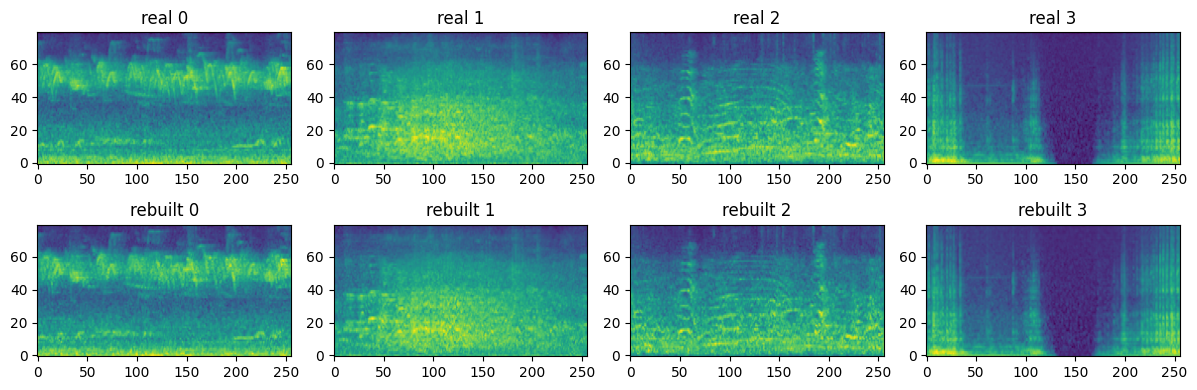

originals


reconstructions


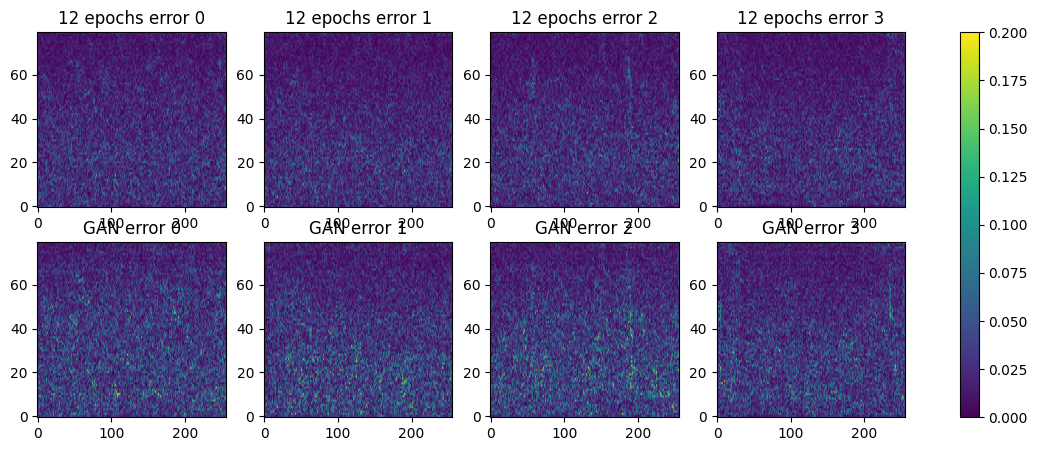

In [19]:
val_data = MelDataset("val")
val_loader = DataLoader(Subset(val_data, [0, 500, 1000, 1500]), batch_size = 4)
real, _ = next(iter(val_loader))
real = real.to(device)
model.eval()
with torch.no_grad():
    mu, _ = model.encoder(real).chunk(2, dim = 1)
    rebuilt = model.decoder(mu).clamp(-1, 1)
print(F.l1_loss(rebuilt, real).item())

fig, axes = plt.subplots(2, 4, figsize = (12, 4))
for i in range(4):
    axes[0, i].imshow(real[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[0, i].set_title(f"real {i}")
    axes[1, i].imshow(rebuilt[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[1, i].set_title(f"rebuilt {i}")
plt.tight_layout()
plt.show()

m = ((real + 1) / 2) * (MAX - MIN) + MIN
print("originals")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

m = ((rebuilt + 1) / 2) * (MAX - MIN) + MIN
print("reconstructions")
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

rows = [("real", real), ("12 epochs", rebuilt_old), ("GAN", rebuilt)]

err_old = (rebuilt_old - real).abs()
err_gan = (rebuilt - real).abs()

fig, axes = plt.subplots(2, 4, figsize = (14, 5))
for i in range(4):
    axes[0, i].imshow(err_old[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto", vmin = 0, vmax = 0.2)
    axes[0, i].set_title(f"12 epochs error {i}")
    im = axes[1, i].imshow(err_gan[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto", vmin = 0, vmax = 0.2)
    axes[1, i].set_title(f"GAN error {i}")
plt.colorbar(im, ax = axes)
plt.show()

In [20]:
model = Autoencoder().to(device)
model.load_state_dict(torch.load(CKPT + "vae_gan2.pt", map_location = device))
model.eval()
all_mels = np.load(DATA + "mels.npy")
all_mels = torch.tensor(all_mels.astype("float32"))
latents = []
for i in range(0, len(all_mels), 64):
  x = all_mels[i:i + 64].to(device)
  with torch.no_grad():
    mu, logvar = model.encoder(x).chunk(2, dim = 1)
  latents.append(mu.cpu().half())
latents = torch.cat(latents).numpy()
np.save("/content/drive/MyDrive/text-to-sound/data/latents.npy", latents)
scale = 1 / latents.astype("float32").std()
print(latents.shape, scale)

(25469, 4, 20, 64) 0.6862992
